# 02 · Sensor simulator: what would our ESP32 node read?

We have no ESP32 data yet. So at every CPCB station we place **3 virtual sensor units** and ask:
*given the true air and weather of this hour, what would each sensor on our board report?*

```
true air + weather (02_clean)  ──►  one formula per sensor  ──►  ESP32 hourly processing  ──►  3_sensors/
                                    (+ each unit's own errors)     (humidity correction, AQI)
```

- This is **not** machine learning: every formula below is physics or a datasheet curve.
- Each unit draws its own errors once (bias, gain, drift), like three real boards would differ.
- The true PM is kept in the output **only as the answer** the models must predict, never as an input.
- Sources for every number: `docs/simulator_sources.md`.

Notation: $U(a,b)$ = random value between a and b, drawn **once per unit**. $\mathcal{N}(0,\sigma)$ = random noise **every hour**.

In [1]:
# imports
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# folders
DATA = Path("../data")
CLEAN = DATA / "2_clean"
OUT = DATA / "3_sensors"
OUT.mkdir(parents=True, exist_ok=True)

UNITS_PER_STATION = 3

In [3]:
# a random-number generator that gives the same numbers every run for the same (station, unit)
def make_rng(station, unit):
    seed = int(hashlib.sha256(f"20260926/{station}/{unit}".encode()).hexdigest()[:16], 16)
    return np.random.default_rng(seed)


def U(rng, low, high):
    return float(rng.uniform(low, high))

## 1. The true air that every unit at a station breathes

**Aerosol water uptake κ** (how much particles swell in humid air) changes slowly over days:
$$\kappa_t = 0.30 + 0.10\,z_t,\qquad z_t = \phi\,z_{t-1} + \sqrt{1-\phi^2}\,\varepsilon_t,\quad \phi = e^{-1/48}$$
(mean 0.30, Delhi measurements 0.05-0.77; changes over ~48 h)

**VOC** (for the SGP41) is not measured by CPCB, so we tie it to traffic CO:
$$VOC_{ppb} = 20 + r \cdot CO_{ppb},\qquad r = U(0.03, 0.10)\ \text{per station}$$

In [4]:
# kappa: slowly changing aerosol water uptake
def kappa_series(n, rng):
    phi = np.exp(-1 / 48)
    z = np.zeros(n)
    z[0] = rng.normal()
    noise = rng.normal(0, np.sqrt(1 - phi**2), n)
    for i in range(1, n):
        z[i] = phi * z[i - 1] + noise[i]
    return np.clip(0.30 + 0.10 * z, 0.05, 0.77)

In [5]:
# gas sensors need a gas value every hour: fill short gaps, then use the usual value for that month and hour
def fill_gas(gas, ts, network_typical):
    month = ts.dt.tz_convert("Asia/Kolkata").dt.month
    hour = ts.dt.tz_convert("Asia/Kolkata").dt.hour
    key = pd.MultiIndex.from_arrays([month, hour])
    filled = gas.interpolate(limit=3, limit_area="inside")
    station_typical = gas.groupby([month, hour]).median()
    filled = filled.fillna(pd.Series(station_typical.reindex(key).to_numpy(), index=gas.index))
    filled = filled.fillna(pd.Series(network_typical.reindex(key).to_numpy(), index=gas.index))
    return filled.to_numpy()

## 2. One formula per sensor

### 2.1 SPS30 — particulate matter (PM1, PM2.5, PM10)
Three effects, calibrated so that the SPS30-vs-reference slope matches an IIT-Delhi field study (1.46-1.86):

1. **Humid particles look bigger** (κ-Köhler growth, Crilley 2018). The air inside the sensor is a bit warmer
   ($\Delta T$), which lowers the RH the particles see:
   $$C = 1 + \frac{\kappa/1.65}{1/a_w - 1},\qquad a_w = \min(RH_{inside}/100,\ 0.97)$$
2. **Dust is almost invisible** to the SPS30 (efficiency $e$); dust = part of the coarse mass:
   $$\text{dust}_{2.5} = \min(0.25\,(PM_{10}-PM_{2.5}),\ PM_{2.5}),\qquad \text{fine} = PM_{2.5} - \text{dust}_{2.5}$$
3. **It reads high** (scale $s$), PM10 is mostly guessed from small particles:
   $$PM_{2.5}^{sps} = s\,(\text{fine}\cdot C + e\cdot\text{dust}_{2.5}) + \mathcal{N}(0,\ 0.05x + 1)$$
   $$PM_{10}^{sps} = PM_{2.5}^{sps}(1+q) + s\,f\,(PM_{10}-PM_{2.5}),\qquad PM_{1}^{sps} = r\,s\,\text{fine}\cdot C$$

| parameter | value | source |
|---|---|---|
| $s$ | U(1.15, 1.55) | IIT-Delhi field study, SCAQMD |
| $\Delta T$ | U(1.5, 3.5) °C | needed to match field R² ≈ 0.9 |
| $e$ | U(0.20, 0.40) | Gautam 2025 (dust storm) |
| $q,\ f,\ r$ | U(0.02, 0.10), U(0.05, 0.25), U(0.75, 0.95) | Kuula 2020 |
| fog (RH > 95 %) | extra + U(0, 0.20) | spec |

In [6]:
# SPS30: draw this unit's own errors
def sps30_params(rng):
    return dict(scale=U(rng, 1.15, 1.55), dt_inside=U(rng, 1.5, 3.5), dust_eff=U(rng, 0.20, 0.40),
                pm10_q=U(rng, 0.02, 0.10), coarse_f=U(rng, 0.05, 0.25), pm1_r=U(rng, 0.75, 0.95),
                fog_bias=U(rng, 0.0, 0.20))

In [7]:
# SPS30: true PM -> what the sensor reports
def sps30(pm25_true, pm10_true, rh_inside, kappa, p, rng):
    coarse = np.maximum(pm10_true - pm25_true, 0)
    dust = np.minimum(0.25 * coarse, pm25_true)
    fine = pm25_true - dust
    aw = np.clip(rh_inside / 100, 0, 0.97)
    growth = 1 + (kappa / 1.65) / (1 / np.maximum(aw, 1e-9) - 1)
    fog = np.where(rh_inside > 95, 1 + rng.uniform(0, p["fog_bias"], len(rh_inside)), 1.0)

    pm25 = p["scale"] * (fine * growth + p["dust_eff"] * dust) * fog
    pm25 = pm25 + rng.normal(0, 0.05 * np.abs(pm25) + 1)
    pm10 = pm25 * (1 + p["pm10_q"]) + p["scale"] * p["coarse_f"] * coarse
    pm1 = p["pm1_r"] * p["scale"] * fine * growth * fog + rng.normal(0, 0.05 * np.abs(pm25) + 1)

    pm25 = np.clip(pm25, 0, 1000)
    pm10 = np.clip(np.maximum(pm10, pm25), 0, 1000)     # PM10 always includes PM2.5
    pm1 = np.clip(np.minimum(pm1, pm25), 0, 1000)       # PM1 is part of PM2.5
    return pm1, pm25, pm10

### 2.2 HDC1080 — temperature and humidity
The sun heats the radiation shield, less when the wind cools it (Nakamura & Mahrt 2005):
$$T = T_{true} + b_T + c\,\frac{SW/1000}{1 + k\,ws} + \mathcal{N}(0, 0.3)$$
RH follows from the true dew point at the (warmer) sensor temperature, plus the datasheet error:
$$RH = RH(T_d, T) + b_{RH} + \mathcal{N}(0, 2)$$

| parameter | value | source |
|---|---|---|
| $b_T$ | U(-0.5, 0.5) °C | datasheet |
| $c$ | U(1.0, 2.5) °C per kW/m² | Nakamura & Mahrt |
| $b_{RH}$ | U(-2, 2) % | datasheet |

In [8]:
# RH (%) of air with dew point td at temperature t (Magnus formula)
def rh_from_dewpoint(td, t):
    return 100 * np.exp(17.625 * td / (243.04 + td) - 17.625 * t / (243.04 + t))

In [9]:
# HDC1080: draw errors / simulate
def hdc1080_params(rng):
    return dict(t_bias=U(rng, -0.5, 0.5), sun_heat=U(rng, 1.0, 2.5), rh_bias=U(rng, -2, 2))


def hdc1080(t_true, td_true, sun, wind_at_sensor, p, rng):
    n = len(t_true)
    heating = p["sun_heat"] * (np.nan_to_num(sun) / 1000) / (1 + np.nan_to_num(wind_at_sensor))
    t = t_true + p["t_bias"] + heating + rng.normal(0, 0.3, n)
    rh = rh_from_dewpoint(td_true, t) + p["rh_bias"] + rng.normal(0, 2, n)
    return t, np.clip(rh, 0, 100)

### 2.3 BMP280 — pressure
Pressure drops about 1 hPa per 8.3 m of height (the node sits on a roof):
$$P = P_{true} - \frac{h}{8.3} + b_P + \mathcal{N}(0, 0.1)$$
| $h$ | U(3, 25) m | $b_P$ | U(-1, 1) hPa (datasheet) |
|---|---|---|---|

In [10]:
# BMP280: draw errors / simulate
def bmp280_params(rng):
    return dict(height=U(rng, 3, 25), bias=U(rng, -1, 1))


def bmp280(p_true, p, rng):
    return p_true - p["height"] / 8.3 + p["bias"] + rng.normal(0, 0.1, len(p_true))

### 2.4 Anemometer + wind vane
Roof-top buildings shelter the cups (factor $k$); cups stop below 0.3 m/s; the vane is mounted a bit off north:
$$ws = k\,ws_{true} + \mathcal{N}(0, 0.3)\ \ (0 \text{ if } < 0.3),\qquad wd = wd_{true} + \delta + \mathcal{N}(0, 15°)$$
| $k$ | U(0.4, 1.0) | $\delta$ | U(-15°, 15°) |
|---|---|---|---|

In [11]:
# anemometer: draw errors / simulate
def wind_params(rng):
    return dict(shelter=U(rng, 0.4, 1.0), offset=U(rng, -15, 15))


def anemometer(ws_true, wd_true, p, rng):
    n = len(ws_true)
    ws = p["shelter"] * ws_true + rng.normal(0, 0.3, n)
    ws = np.where(ws < 0.3, 0, ws)
    wd = (wd_true + p["offset"] + rng.normal(0, 15, n)) % 360
    return ws, wd

### 2.5 Rain board
Wet (1) while it rains (> 0.1 mm/h), then dries linearly over $D$ hours; fog sometimes wets it (2 % of hours with RH > 90 %):
$$\text{wet} = \begin{cases}1 & \text{raining}\\ \max(0,\ 1 - (h_{since}-1)/D) & \text{otherwise}\end{cases}$$
| $D$ | U(1, 2) h |
|---|---|

In [12]:
# rain board: draw errors / simulate
def rain_params(rng):
    return dict(dry_hours=U(rng, 1, 2))


def rain_board(precip, rh, p, rng):
    raining = np.nan_to_num(precip) > 0.1
    hours_since_rain = np.full(len(precip), np.inf)
    last_rain = -np.inf
    for i in range(len(precip)):
        if raining[i]:
            last_rain = i
        hours_since_rain[i] = i - last_rain
    wet = np.where(raining, 1.0, np.clip(p["dry_hours"] - (hours_since_rain - 1), 0, 1))
    fog = (wet == 0) & (np.nan_to_num(rh) > 90) & (rng.random(len(precip)) < 0.02)
    return np.where(fog, rng.uniform(0.2, 1.0, len(precip)), wet)

### 2.6 BH1750 — light
Sunlight (W/m²) times the luminous efficacy (≈ 108 lm/W, Littlefair 1985), dimmed by smog:
$$lux = g \cdot 108 \cdot SW \cdot e^{-\beta\,PM_{2.5}/100} + \mathcal{N}(0, 50),\qquad 0 \text{ at night}$$
| $g$ (mounting/shade) | U(0.6, 1.2) | $\beta$ | U(0, 0.2) |
|---|---|---|---|

In [13]:
# BH1750: draw errors / simulate
def bh1750_params(rng):
    return dict(gain=U(rng, 0.6, 1.2), smog_dim=U(rng, 0.0, 0.2))


def bh1750(sun, pm25_true, p, rng):
    lux = p["gain"] * 108 * sun * np.exp(-p["smog_dim"] * np.nan_to_num(pm25_true) / 100)
    lux = lux + rng.normal(0, 50, len(sun))
    lux = np.where(sun < 1, 0, lux)
    return np.clip(lux, 0, 121557)

### 2.7 MQ-7 (CO) and MQ-135 (air quality) — metal-oxide gas sensors
Datasheet curves are straight lines on log-log paper, plus temperature/humidity effects and slow drift:
$$\ln R_s = \ln R_0 + b\,\ln(\text{gas} + c_0) + g_T (T-20) + g_{RH}(RH-65) + d\cdot\text{days} + \mathcal{N}(0, 0.05)$$
- MQ-7: gas = CO (ppm).
- MQ-135: gas = $w_{CO}\,CO + w_{VOC}\,VOC/1000$, and NO2 (oxidising) **raises** $R_s$: extra $+\,g_{ox}\ln(1 + NO_2/20)$.

| parameter | MQ-7 | MQ-135 | source |
|---|---|---|---|
| $R_0$ | lognormal, median 20 kΩ | median 30 kΩ | datasheets |
| slope $b$ | U(-0.70, -0.45) | U(-0.55, -0.40) | datasheet Fig. 3 |
| background $c_0$ (H2) | U(0.3, 1.0) ppm | U(0.3, 1.0) ppm | Novelli 1999 |
| $g_T$, $g_{RH}$ | U(-0.016, -0.007), U(-0.008, -0.003) | same | datasheet Fig. 4 |
| drift $d$ per day | U(-0.001, 0.001) | same | spec |

In [14]:
# MQ-7 / MQ-135: draw errors
def mq_params(rng, r0_median):
    return dict(r0=r0_median * np.exp(rng.normal(0, 0.5)), b=None, c0=U(rng, 0.3, 1.0),
                g_t=U(rng, -0.016, -0.007), g_rh=U(rng, -0.008, -0.003), drift=U(rng, -0.001, 0.001))


def mq7_params(rng):
    p = mq_params(rng, 20000)
    p["b"] = U(rng, -0.70, -0.45)
    return p


def mq135_params(rng):
    p = mq_params(rng, 30000)
    p.update(b=U(rng, -0.55, -0.40), w_co=U(rng, 0.1, 0.5), w_voc=U(rng, 0.5, 1.5), g_ox=U(rng, 0.0, 0.15))
    return p

In [15]:
# metal-oxide sensor: gas -> resistance (formula above)
def mos_resistance(gas_ppm, t, rh, days, p, rng):
    ln_rs = (np.log(p["r0"]) + p["b"] * np.log(gas_ppm + p["c0"]) + p["g_t"] * (t - 20)
             + p["g_rh"] * (rh - 65) + p["drift"] * days + rng.normal(0, 0.05, len(gas_ppm)))
    return np.exp(ln_rs)


def mq7(co_ppm, t, rh, days, p, rng):
    return mos_resistance(co_ppm, t, rh, days, p, rng)


def mq135(co_ppm, voc_ppb, no2_ppb, t, rh, days, p, rng):
    gas = p["w_co"] * co_ppm + p["w_voc"] * voc_ppb / 1000
    return mos_resistance(gas, t, rh, days, p, rng) * np.exp(p["g_ox"] * np.log1p(np.nan_to_num(no2_ppb) / 20))

### 2.8 SGP41 — VOC and NOx (raw "ticks")
The raw signal is proportional to log(resistance) (Sensirion datasheet): VOC ticks **fall** when VOC rises,
NOx ticks **rise** with oxidising gases (NO2 and ozone):
$$VOC_{ticks} = B_V - k_V\ln(1 + VOC/100) + k_{ox}\ln(1 + (NO_2+O_3)/50) + \text{drift} + \mathcal{N}(0, 50)$$
$$NOx_{ticks} = B_N + k_N\ln\!\left(1 + \frac{NO_2 + w\,O_3}{10}\right) + \text{drift} + \mathcal{N}(0, 30)$$

| parameter | value | source |
|---|---|---|
| $B_V$, $B_N$ | U(25000, 35000), U(14000, 17000) | spec / datasheet example |
| $k_V$ | U(1040, 1507) | datasheet: -710…-1030 ticks per doubling |
| $k_N$ | U(1437, 3039) | datasheet: +950…+2010 ticks per doubling |
| $k_{ox}$, $w$ | U(0, 700), U(2, 5) | datasheet Fig. 2-3 |
| drift | U(-5, 5) ticks/day | TODO_VERIFY |

In [16]:
# SGP41: draw errors / simulate
def sgp41_params(rng):
    return dict(voc_base=U(rng, 25000, 35000), voc_k=U(rng, 1040, 1507), voc_k_ox=U(rng, 0, 700),
                nox_base=U(rng, 14000, 17000), nox_k=U(rng, 1437, 3039), nox_w_o3=U(rng, 2.0, 5.0),
                drift=U(rng, -5, 5))


def sgp41(voc_ppb, no2_ppb, o3_ppb, days, p, rng):
    n = len(voc_ppb)
    oxidants = np.nan_to_num(no2_ppb) + np.nan_to_num(o3_ppb)
    voc = (p["voc_base"] - p["voc_k"] * np.log1p(voc_ppb / 100) + p["voc_k_ox"] * np.log1p(oxidants / 50)
           + p["drift"] * days + rng.normal(0, 50, n))
    nox = (p["nox_base"] + p["nox_k"] * np.log1p((no2_ppb + p["nox_w_o3"] * o3_ppb) / 10)
           + p["drift"] * days + rng.normal(0, 30, n))
    return np.clip(np.round(voc), 0, 65535), np.clip(np.round(nox), 0, 65535)

### 2.9 Sensor faults
Each hour has a 1 % chance of a missing PM reading, and about once a year the SPS30 is down for U(6, 48) hours.
(Hours where CPCB itself has no PM are simply missing — that is not a sensor fault.)

In [17]:
# SPS30 faults: random missing hours + long outages
def sps30_faults(n, rng):
    missing = rng.random(n) < 0.01
    outage = np.zeros(n, dtype=bool)
    for _ in range(rng.poisson(n / 8766)):            # ~1 outage per year
        length = round(U(rng, 6, 48))
        start = int(rng.integers(0, n - length))
        outage[start:start + length] = True
    return missing, outage

## 3. What the ESP32 does every hour (same code will run on the device)

| step | formula |
|---|---|
| humidity correction of PM | $PM_{corr} = PM_{sps} / C(RH, \kappa = 0.4)$ (fixed κ until we calibrate) |
| coarse ratio | $(PM_{10}-PM_{2.5}) / \max(PM_1, 1)$ |
| dust flag | coarse ratio > 0.5 and RH < 60 % |
| gas baselines | clean-air level = 90 % quantile of the last 7 days (NOx: 10 %) |
| PM state | ok / filled (1 h hole) / Model B fallback (≤ 24 h) / unavailable |
| CPCB AQI | from 24-h means, needs ≥ 16 measured hours |

In [18]:
# humidity correction (the device uses one fixed kappa = 0.4)
def humidity_correct(pm, rh):
    aw = np.clip(rh / 100, 0, 0.95)
    growth = 1 + (0.4 / 1.65) / (1 / np.maximum(aw, 1e-9) - 1)
    return pm / growth

In [19]:
# clean-air baseline of a gas sensor: quantile of the previous 7 days
def rolling_baseline(x, q):
    return pd.Series(x).shift(1).rolling(168, min_periods=24).quantile(q).to_numpy()

In [20]:
# PM state from how many hours the SPS30 has been silent
def pm_state(pm_measured):
    m = pd.Series(pm_measured)
    hours_lost = (~m).groupby(m.cumsum()).cumsum().to_numpy()
    return np.select([hours_lost == 0, hours_lost <= 1, hours_lost <= 24],
                     ["ok", "filled_le_1h", "fallback_model_b"], "unavailable")

**CPCB AQI** (India): each pollutant's 24-h mean is mapped linearly inside its band, AQI = the larger sub-index.

| AQI band | 0-50 | 51-100 | 101-200 | 201-300 | 301-400 | 401-500 |
|---|---|---|---|---|---|---|
| PM2.5 (µg/m³) | 0-30 | 31-60 | 61-90 | 91-120 | 121-250 | 250+ |
| PM10 (µg/m³) | 0-50 | 51-100 | 101-250 | 251-350 | 351-430 | 430+ |



$$
I = I_{lo} + \frac{I_{hi} - I_{lo}}{B_{hi} - B_{lo}}(C - B_{lo})
$$

(TODO_VERIFY breakpoints against the official CPCB table)



In [21]:
# CPCB sub-index of one 24-h mean concentration
AQI_BANDS = [(0, 50), (51, 100), (101, 200), (201, 300), (301, 400), (401, 500)]
PM25_LIMITS = [30, 60, 90, 120, 250, 380]
PM10_LIMITS = [50, 100, 250, 350, 430, 510]


def sub_index(c, limits):
    previous = 0.0
    for top, (i_lo, i_hi) in zip(limits, AQI_BANDS):
        if c <= top:
            return i_lo + (i_hi - i_lo) / (top - previous) * (c - previous)
        previous = top
    return 500.0


assert sub_index(30, PM25_LIMITS) == 50 and sub_index(60, PM25_LIMITS) == 100 and sub_index(100, PM10_LIMITS) == 100

In [22]:
# AQI of every hour from the last 24 hours (NaN if fewer than 16 measured hours)
def rolling_aqi(pm25, pm10, measured):
    p25 = pd.Series(np.where(measured, pm25, np.nan))
    p10 = pd.Series(np.where(measured, pm10, np.nan))
    mean25, mean10 = p25.rolling(24, min_periods=1).mean(), p10.rolling(24, min_periods=1).mean()
    count = p25.rolling(24, min_periods=1).count()
    aqi = np.full(len(p25), np.nan)
    for i in np.flatnonzero(count >= 16):
        aqi[i] = round(max(sub_index(mean25[i], PM25_LIMITS), sub_index(mean10[i], PM10_LIMITS)))
    return aqi

## 4. Put it together: one station, one unit

In [23]:
# the true values every unit at this station shares (air, weather, kappa, VOC)
def station_truth(clean, network_typical, station):
    rng = make_rng(station, -1)
    truth = clean[["ts", "pm25", "pm10", "t", "rh", "td", "p", "wind_u", "wind_v", "precip", "swrad"]].copy()
    for gas in ("co_ppm", "no2_ppb", "o3_ppb"):
        truth[gas] = fill_gas(clean[gas], clean.ts, network_typical[gas])
    truth["voc_ppb"] = 20 + U(rng, 0.03, 0.10) * truth.co_ppm * 1000
    truth["kappa"] = kappa_series(len(truth), rng)
    truth["ws"] = np.hypot(truth.wind_u, truth.wind_v)
    truth["wd"] = np.rad2deg(np.arctan2(-truth.wind_u, -truth.wind_v)) % 360
    return truth

In [24]:
# draw all errors of one unit (once, for its whole life)
def draw_unit(rng):
    return {"sps30": sps30_params(rng), "hdc1080": hdc1080_params(rng), "bmp280": bmp280_params(rng),
            "wind": wind_params(rng), "rain": rain_params(rng), "bh1750": bh1750_params(rng),
            "mq7": mq7_params(rng), "mq135": mq135_params(rng), "sgp41": sgp41_params(rng)}

In [25]:
# every sensor of one unit reads the true values
def read_sensors(truth, p, rng):
    days = ((truth.ts - truth.ts.iloc[0]).dt.total_seconds() / 86400).to_numpy()
    g = {c: truth[c].to_numpy(float) for c in truth.columns if c != "ts"}
    r = pd.DataFrame({"ts": truth.ts})
    rh_inside = np.clip(rh_from_dewpoint(g["td"], g["t"] + p["sps30"]["dt_inside"]), 0, 100)
    r["pm1"], r["pm25"], r["pm10"] = sps30(g["pm25"], g["pm10"], rh_inside, g["kappa"], p["sps30"], rng)
    ws, wd = anemometer(g["ws"], g["wd"], p["wind"], rng)
    r["t"], r["rh"] = hdc1080(g["t"], g["td"], g["swrad"], p["wind"]["shelter"] * g["ws"], p["hdc1080"], rng)
    r["p"] = bmp280(g["p"], p["bmp280"], rng)
    r["wind_speed"] = ws
    r["wind_u"], r["wind_v"] = -ws * np.sin(np.deg2rad(wd)), -ws * np.cos(np.deg2rad(wd))
    r["rain_frac"] = rain_board(g["precip"], g["rh"], p["rain"], rng)
    r["lux"] = bh1750(g["swrad"], g["pm25"], p["bh1750"], rng)
    r["mq7_rs"] = mq7(g["co_ppm"], r.t.to_numpy(), r.rh.to_numpy(), days, p["mq7"], rng)
    r["mq135_rs"] = mq135(g["co_ppm"], g["voc_ppb"], g["no2_ppb"], r.t.to_numpy(), r.rh.to_numpy(), days, p["mq135"], rng)
    r["sraw_voc"], r["sraw_nox"] = sgp41(g["voc_ppb"], g["no2_ppb"], g["o3_ppb"], days, p["sgp41"], rng)
    return r

In [26]:
# the ESP32's hourly processing (section 3)
def process_on_device(r, missing, outage, truth):
    have_truth = truth.pm25.notna().to_numpy() & truth.pm10.notna().to_numpy()
    r["pm_measured"] = have_truth & ~missing & ~outage
    r["pm_state"] = pm_state(r.pm_measured.to_numpy())
    one_hour_hole = r.pm_state.eq("filled_le_1h").to_numpy()
    for c in ("pm1", "pm25", "pm10"):
        value = r[c].where(r.pm_measured)
        r[c] = np.where(one_hour_hole, value.ffill(limit=1), value)
    r["pm25_corr"] = humidity_correct(r.pm25, r.rh)
    r["pm10_corr"] = humidity_correct(r.pm10, r.rh)
    r["coarse_ratio"] = (r.pm10 - r.pm25) / np.maximum(r.pm1, 1)
    r["dust"] = (r.coarse_ratio > 0.5) & (r.rh < 60) & r.pm_measured
    r["Rbase7"], r["Rbase135"] = rolling_baseline(r.mq7_rs, 0.90), rolling_baseline(r.mq135_rs, 0.90)
    r["base_voc"], r["base_nox"] = rolling_baseline(r.sraw_voc, 0.90), rolling_baseline(r.sraw_nox, 0.10)
    r["aqi_pm"] = rolling_aqi(r.pm25_corr.to_numpy(), r.pm10_corr.to_numpy(), r.pm_measured.to_numpy())
    r["sim_outage"] = outage
    return r

In [27]:
# one virtual unit: errors -> sensor readings -> faults -> device processing (+ true PM as the answer)
def simulate_unit(truth, station, unit):
    rng = make_rng(station, unit)
    params = draw_unit(rng)
    readings = read_sensors(truth, params, rng)
    missing, outage = sps30_faults(len(truth), rng)
    record = process_on_device(readings, missing, outage, truth)
    record["true_pm25"], record["true_pm10"] = truth.pm25.to_numpy(), truth.pm10.to_numpy()   # TARGET only
    return record, params

## 5. Run it for every station

In [28]:
# load the clean tables; keep stations with at least one year (8760 h) of BOTH PM2.5 and PM10
# (the SPS30 formula and the targets need both; Sector 16A Faridabad has almost no PM10)
clean = {p.stem: pd.read_parquet(p) for p in sorted(CLEAN.glob("*.parquet"))}
stations = [s for s, df in clean.items() if (df.pm25.notna() & df.pm10.notna()).sum() >= 8760]
print(len(stations), "stations; dropped:", sorted(set(clean) - set(stations)))

32 stations; dropped: ['sector_16a_faridabad_hspcb']


In [29]:
# typical gas level per (month, IST hour) over all stations: fallback for stations without a gas
all_clean = pd.concat(clean[s] for s in stations)
local = all_clean.ts.dt.tz_convert("Asia/Kolkata")
network_typical = {g: all_clean[g].groupby([local.dt.month, local.dt.hour]).median() for g in ("co_ppm", "no2_ppb", "o3_ppb")}
del all_clean

In [30]:
# simulate 3 units per station and save them (skips files that already exist)
unit_table = []
for station in stations:
    truth = station_truth(clean[station], network_typical, station)
    for unit in range(UNITS_PER_STATION):
        path = OUT / f"{station}_u{unit}.parquet"
        if path.exists():
            params = draw_unit(make_rng(station, unit))       # same numbers as when it was simulated
        else:
            record, params = simulate_unit(truth, station, unit)
            record.to_parquet(path, index=False)
        unit_table.append({"station": station, "unit": unit,
                           **{f"{s}.{k}": round(v, 4) for s, d in params.items() for k, v in d.items()}})
pd.DataFrame(unit_table).to_csv(OUT / "units.csv", index=False)
print(len(unit_table), "virtual units")

96 virtual units


## 6. Is it realistic?
**SPS30 vs reference in Delhi winter.** IIT-Delhi field study (Kumar et al. 2025): slope 1.46-1.86, R² ≈ 0.91.
We undo the device correction and fit raw SPS30 PM2.5 against true PM2.5 for every unit.

In [31]:
# slope and R2 of raw SPS30 vs true PM2.5 in winter, per unit
def winter_fit(rec):
    winter = rec.ts.dt.tz_convert("Asia/Kolkata").dt.month.isin([11, 12, 1, 2])
    raw = rec.pm25_corr * (1 + (0.4 / 1.65) / (1 / np.clip(rec.rh / 100, 1e-9, 0.95) - 1))
    ok = winter & rec.pm_state.eq("ok") & raw.notna() & rec.true_pm25.notna()
    slope = np.polyfit(rec.true_pm25[ok], raw[ok], 1)[0]
    r2 = np.corrcoef(rec.true_pm25[ok], raw[ok])[0, 1] ** 2
    return slope, r2


fits = pd.DataFrame([winter_fit(pd.read_parquet(p)) for p in sorted(OUT.glob("*_u*.parquet"))], columns=["slope", "r2"])
fits.describe().round(2)

,slope,r2
count,96.00,96.00
mean,1.77,0.86
std,0.15,0.03
min,1.50,0.78
25%,1.66,0.84
50%,1.75,0.86
75%,1.88,0.89
max,2.09,0.93


In [32]:
# check: the median slope must be inside the field range
print(f"median slope {fits.slope.median():.2f}, median R2 {fits.r2.median():.2f}, "
      f"units inside 1.46-1.86: {fits.slope.between(1.46, 1.86).mean():.0%}")
assert 1.46 <= fits.slope.median() <= 1.86

median slope 1.75, median R2 0.86, units inside 1.46-1.86: 71%


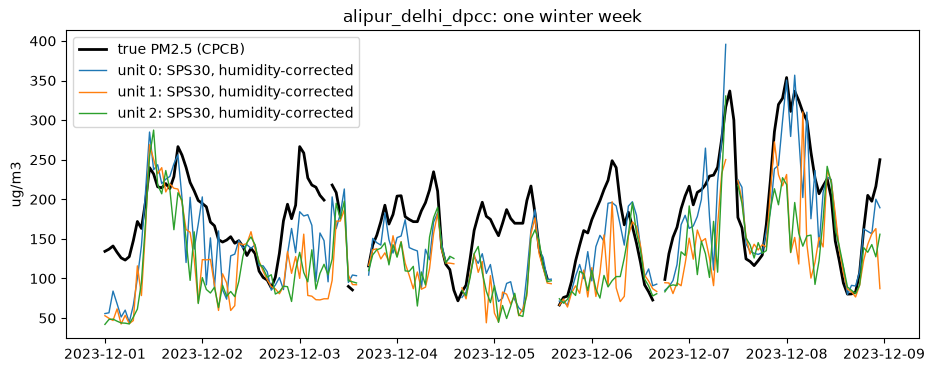

In [33]:
# one winter week: true PM2.5 vs what the 3 units of one station report
station = stations[0]
plt.figure(figsize=(11, 4))
for unit in range(3):
    rec = pd.read_parquet(OUT / f"{station}_u{unit}.parquet").set_index("ts").tz_convert("Asia/Kolkata").loc["2023-12-01":"2023-12-08"]
    if unit == 0:
        plt.plot(rec.index, rec.true_pm25, "k", lw=2, label="true PM2.5 (CPCB)")
    plt.plot(rec.index, rec.pm25_corr, lw=1, label=f"unit {unit}: SPS30, humidity-corrected")
plt.title(f"{station}: one winter week")
plt.ylabel("ug/m3")
plt.legend()
plt.show()

In [34]:
# do the gas sensors follow their gas? (correlation with the true value at one station)
rec = pd.read_parquet(OUT / f"{station}_u0.parquet").merge(clean[station][["ts", "co_ppm", "no2_ppb", "o3_ppb", "swrad"]], on="ts")
checks = {"MQ-7 ln(Rs/Rbase) vs ln CO": (np.log(rec.mq7_rs / rec.Rbase7), np.log(rec.co_ppm.clip(lower=0.05))),
          "SGP41 NOx vs NO2+O3": (rec.sraw_nox - rec.base_nox, np.log1p((rec.no2_ppb + 3.5 * rec.o3_ppb) / 10)),
          "BH1750 vs sunshine": (np.log1p(rec.lux), rec.swrad)}
for name, (a, b) in checks.items():
    both = pd.DataFrame({"a": a, "b": b}).replace([np.inf, -np.inf], np.nan).dropna()
    print(f"{name:30s} r = {both.a.corr(both.b):+.2f}")

MQ-7 ln(Rs/Rbase) vs ln CO     r = -0.74
SGP41 NOx vs NO2+O3            r = +0.88
BH1750 vs sunshine             r = +0.79
